# CatBoost Hyperparameter Tuning

## 1. Objective

The objective of this notebook is to tune CatBoost for predicting restaurant `weighted_rating`, using only the training data and 5-fold cross-validation.

The best settings, their validation scores and a refit model are meant to feed the ensemble notebook.

## 2. Problem Statement

This project predicts the weighted rating of a restaurant from the prepared restaurant features (cuisine, location, menu, pricing and geography).

**Target Variable:** `weighted_rating`

**Problem Type:** Supervised Machine Learning - Regression

## 3. Evaluation Metrics

The models are evaluated with:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE), the main metric for choosing settings
- R-squared (R²)

Every score is the mean and standard deviation over the same 5 folds (`KFold`, `shuffle=True`, `random_state=42`). The standard deviation is the population standard deviation (`ddof=0`) of the 5 fold scores, the same convention the search already used.

## 4. Approach

CatBoost is a gradient-boosting model. It builds many small trees one after another, and each new tree tries to fix the mistakes of the earlier ones. It handles categorical columns directly.

Tuning uses random search. Each trial draws one set of settings from the ranges in step 3 (fixed seed, so the draws can be repeated) and scores it with 5-fold cross-validation on the training rows. The mean RMSE is the only score used to choose. Random search was kept because it needs no extra library, is repeatable from one seed, and covers the space without assuming its shape.

After the search, the best settings are run through 5-fold cross-validation once more to record MAE, RMSE and R² for every fold. Then the model is refit on all training rows.

A full run of 15 trials takes roughly 25 to 45 minutes, because every trial is 5 model fits on 53,574 rows. `QUICK = True` runs fewer trials.

## 5. Expected Outcome

A set of best settings, a validation table with mean ± std for MAE, RMSE and R², and a model refit on the full training split.

## 6. How the test set was used

The test set is not used in this notebook. It is not loaded, and it plays no part in any choice here. All tuning and all choices use only the training data with 5-fold cross-validation. The test set is used once, at the end of the project, for the single final chosen model or ensemble, in the last cell of the ensemble notebook.

## 1. Imports and configuration

The seed, number of folds and search budget are set here. Prepared CatBoost training features and the target are loaded from `data/processed`, as produced by the project's preprocessing workflow. This notebook does not rebuild preprocessing or load test data.

In [1]:
import os, time, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)

# ================================ CONFIG ================================
PROCESSED_DIR = Path("data/processed")

TARGET = "weighted_rating"
RANDOM_STATE = 42
CV_FOLDS = 5

SAMPLE_ROWS = None   # Keep None to use all training rows; a subset is only for a dry run
QUICK = False        # The recorded experiment used 6 random-search trials

if QUICK:
    N_TRIALS, TIME_BUDGET_MIN = 4, 10
else:
    N_TRIALS, TIME_BUDGET_MIN = 6, None

print("Training data :", PROCESSED_DIR)
print(f"Search budget : {N_TRIALS} random trials x {CV_FOLDS} folds")


Training data : data\processed
Search budget : 6 random trials x 5 folds


## 2. Load the prepared training data

This notebook loads `X_train_catboost.csv` and `y_train.csv` from `data/processed`, as produced by the project's preprocessing workflow. It does not recreate preprocessing and does not load or use test data.

**Evaluation split (updated):** the original training data is split once into 80% development (`X_train`, `y_train`) and 20% validation (`X_val`, `y_val`, seed 42). The search and all 5-fold CV use the development data only. The validation rows are scored once for the selected settings, and the final model is refit on 100% of the original training data (`X_full`, `y_full`). The test set is never loaded.

In [2]:
PROCESSED_FILES = ["X_train_catboost.csv", "y_train.csv"]
missing = [name for name in PROCESSED_FILES if not (PROCESSED_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in '{PROCESSED_DIR}'. "
        "Run the project's preprocessing workflow first to create the processed CatBoost training files."
    )

X_train = pd.read_csv(PROCESSED_DIR / "X_train_catboost.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")

if len(X_train) != len(y_train):
    raise ValueError("X_train and y_train have different numbers of rows.")

cfg_path = PROCESSED_DIR / "catboost_config.joblib"
if cfg_path.exists():
    import joblib
    cat_cols = joblib.load(cfg_path)["categorical_features"]
else:
    cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

FIT_KWARGS = {"cat_features": cat_cols}

print("Loaded prepared CatBoost training data from:", PROCESSED_DIR)
print("Train:", X_train.shape)
print("Categorical features:", cat_cols)

# ---- Evaluation split: 80% development / 20% validation (hold-out) ----
# Tuning and 5-fold CV use ONLY the development rows. X_full / y_full (100% of the original
# training data) are used only for the final refit. The test set is never loaded.
from sklearn.model_selection import train_test_split
VAL_SIZE = 0.20
X_full, y_full = X_train.copy(), y_train.copy()
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=VAL_SIZE, random_state=RANDOM_STATE, shuffle=True)
X_train, X_val = X_train.reset_index(drop=True), X_val.reset_index(drop=True)
y_train, y_val = y_train.reset_index(drop=True), y_val.reset_index(drop=True)
print(f"Development (tuning + CV): {X_train.shape} | Validation (held out): {X_val.shape} | Full train (final refit only): {X_full.shape}")


Loaded prepared CatBoost training data from: data\processed
Train: (53574, 124)
Categorical features: ['geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']
Development (tuning + CV): (42859, 124) | Validation (held out): (10715, 124) | Full train (final refit only): (53574, 124)


## 3. Search space

Each trial draws one value for each setting from these ranges.

| Parameter | Range | What it does |
|---|---|---|
| `iterations` | 300 to 1200 (step 100) | Number of boosting rounds |
| `learning_rate` | 0.02 to 0.15 (log scale) | Step size per round |
| `depth` | 4 to 8 | Tree depth |
| `l2_leaf_reg` | 1 to 20 (log scale) | L2 regularisation on leaf values |
| `border_count` | 64, 128 or 254 | How finely numeric features are split |

## 4. Random search

The following cell executes the complete 6-trial random search. Each trial is scored with the same 5-fold training-only cross-validation split. A checkpoint is saved after every completed trial, allowing an interrupted search to resume without repeating completed trials.

In [ ]:
def sample_params(rng):
    """Draw one configuration. Learning rate and L2 are sampled on a log scale,
    because the useful ranges span an order of magnitude."""
    return {
        "iterations": int(rng.choice([300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200])),
        "learning_rate": float(10 ** rng.uniform(np.log10(0.02), np.log10(0.15))),
        "depth": int(rng.randint(4, 9)),
        "l2_leaf_reg": float(10 ** rng.uniform(np.log10(1.0), np.log10(20.0))),
        "border_count": int(rng.choice([64, 128, 254])),
    }


def make_model(**params):
    settings = dict(loss_function="RMSE", random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
    settings.update(params)
    return CatBoostRegressor(**settings)


X_values = np.asarray(y_train)

if SAMPLE_ROWS:
    keep = np.random.RandomState(RANDOM_STATE).choice(
        len(X_train), min(SAMPLE_ROWS, len(X_train)), replace=False)
    X_fit, y_fit = X_train.iloc[keep], X_values[keep]
    print(f"SAMPLE_ROWS is active - CV on {len(keep):,} rows. Dry run only, not for results.")
else:
    X_fit, y_fit = X_train, X_values
    print(f"5-fold CV on the full training split: {len(X_fit):,} rows")

cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_fit))


def cv_score(params):
    """Mean and standard deviation of the 5-fold CV RMSE for one configuration."""
    fold_rmses = []
    for tri, tei in cv_folds:
        model = make_model(**params)
        model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
        pred = model.predict(X_fit.iloc[tei])
        fold_rmses.append(float(np.sqrt(mean_squared_error(y_fit[tei], pred))))
    return float(np.mean(fold_rmses)), float(np.std(fold_rmses))


# Save one atomic checkpoint after each completed trial. If a trial is
# interrupted, the last completed checkpoint is loaded and that trial is retried.
CHECKPOINT_DIR = Path("artifacts")
CHECKPOINT_PATH = CHECKPOINT_DIR / "catboost_search_checkpoint.pkl"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

SEARCH_CONFIG = {
    "n_trials": N_TRIALS,
    "random_state": RANDOM_STATE,
    "val_size": VAL_SIZE,
    "n_dev_rows": len(X_train),
    "cv_folds": CV_FOLDS,
    "sample_rows": SAMPLE_ROWS,
    "n_rows": len(X_fit),
    "n_features": X_fit.shape[1],
    "feature_columns": list(X_fit.columns),
    "categorical_features": list(cat_cols),
}

def save_search_checkpoint():
    """Atomically save completed trials and all state needed to resume."""
    payload = {
        "config": SEARCH_CONFIG,
        "trials": TRIALS,
        "rng_state": rng.get_state(),
        "best_params": best_params,
        "cv_rmse": cv_rmse,
        "cv_std": cv_std,
    }
    temporary_path = CHECKPOINT_PATH.with_suffix(".tmp")
    with open(temporary_path, "wb") as file:
        pickle.dump(payload, file, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(temporary_path, CHECKPOINT_PATH)


rng = np.random.RandomState(RANDOM_STATE)
if CHECKPOINT_PATH.exists():
    with open(CHECKPOINT_PATH, "rb") as file:
        saved = pickle.load(file)

    if saved.get("config") != SEARCH_CONFIG:
        raise ValueError(
            f"An existing checkpoint was found at {CHECKPOINT_PATH}, but its "
            "search/data configuration does not match this run. Move or delete "
            "that checkpoint to intentionally start a fresh search."
        )

    TRIALS = saved["trials"]
    rng.set_state(saved["rng_state"])
    best_params = saved["best_params"]
    cv_rmse = saved["cv_rmse"]
    cv_std = saved["cv_std"]
    print(f"Resuming from checkpoint: {len(TRIALS)}/{N_TRIALS} trials already complete.")
else:
    TRIALS = []
    best_params, cv_rmse, cv_std = None, float("inf"), float("nan")
    print("No checkpoint found. Starting a new random search.")

T0 = time.time()
for trial in range(len(TRIALS), N_TRIALS):
    if TIME_BUDGET_MIN and (time.time() - T0) / 60 > TIME_BUDGET_MIN:
        print(f"\nTime budget of {TIME_BUDGET_MIN} min reached - stopping after {trial} trials.")
        break

    params = sample_params(rng)
    score, spread = cv_score(params)
    TRIALS.append({**params, "cv_rmse": score, "fold_std": spread})

    improved = score < cv_rmse
    if improved:
        best_params, cv_rmse, cv_std = params, score, spread

    save_search_checkpoint()
    print(f"trial {trial + 1:2d} | RMSE {score:.5f} (std {spread:.5f}) | best {cv_rmse:.5f}"
          + ("   <- best" if improved else ""))
    print(f"  Checkpoint saved ({len(TRIALS)}/{N_TRIALS} trials).")

print(f"\nFinished {len(TRIALS)}/{N_TRIALS} trials in {(time.time() - T0) / 60:.1f} min")
print(f"Checkpoint: {CHECKPOINT_PATH}")


5-fold CV on the full training split: 42,859 rows
No checkpoint found. Starting a new random search.


## 5. Search results

The best mean RMSE, the settings that produced it and the full trial table. The code is unchanged. The printed table heading in the saved output comes from an earlier version of the code and updates on re-run.

In [ ]:
trial_table = pd.DataFrame(TRIALS)
trial_table.insert(0, "trial", range(1, len(trial_table) + 1))
trials_df = trial_table.sort_values("cv_rmse").reset_index(drop=True)

print(f"Best 5-fold CV RMSE : {cv_rmse:.5f}")
print(f"Fold-to-fold std    : {cv_std:.5f}")
print("Best parameters     :")
for key, value in best_params.items():
    print(f"  {key:18s} {value}")

print("\nAll trials by CV RMSE:")
display(trials_df.round(5))

Best 5-fold CV RMSE : 0.13571
Fold-to-fold std    : 0.00104
Best parameters     :
  iterations         900
  learning_rate      0.09955289826724432
  depth              6
  l2_leaf_reg        10.337163339642634
  border_count       64

Top 10 trials by CV RMSE:


,trial,iterations,learning_rate,depth,l2_leaf_reg,border_count,cv_rmse,fold_std
0,1,900,0.09955,6,10.33716,64,0.13571,0.00104
1,4,1000,0.10702,5,1.72409,64,0.13594,0.00104
2,2,900,0.04911,6,3.95819,64,0.13656,0.00110
3,6,1200,0.02197,7,2.99673,128,0.13691,0.00107
4,5,300,0.03692,8,3.64732,64,0.13882,0.00107
5,3,600,0.02667,6,1.06361,128,0.13885,0.00103


## 6. Convergence

Each point is one trial's mean RMSE, and the line is the best score so far. The code is unchanged.

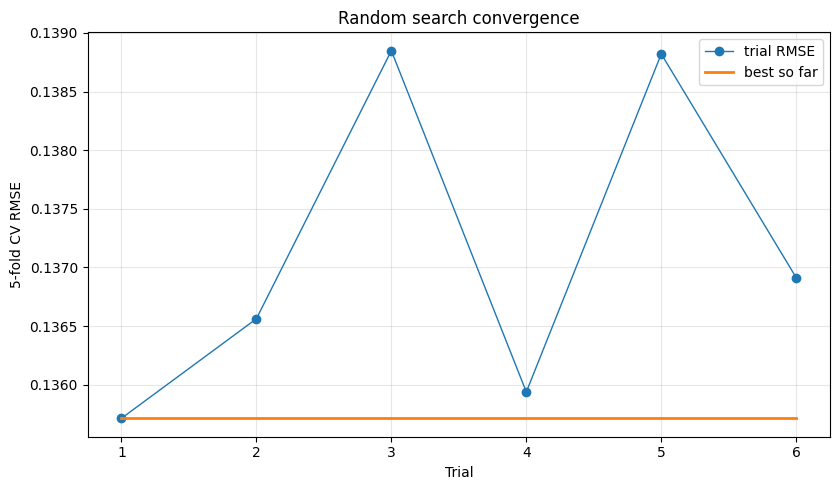

Best configuration found at trial 1 of 6.
If the best-so-far line flattened well before the last trial, the budget was already enough.


In [ ]:
history = trial_table.sort_values("trial")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(history["trial"], history["cv_rmse"], marker="o", linewidth=1, label="trial RMSE")
ax.plot(history["trial"], history["cv_rmse"].cummin(), linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Random search convergence")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

best_trial_number = int(history.loc[history["cv_rmse"].idxmin(), "trial"])
print(f"Best configuration found at trial {best_trial_number} of {len(history)}.")
print("The best-so-far line stayed flat after trial 1, so the later trials added compute but not a better setting.")

### Observation

- The recorded experiment contains **6 random-search trials**. The search budget for this notebook is therefore set to six trials.
- Trial RMSE ranged from 0.13571 to 0.13885, a spread of 0.00314.
- The best setting was trial 1, with mean 5-fold RMSE **0.13571** and fold standard deviation **0.00104**.
- The second-best trial scored 0.13594, which is 0.00023 higher. Four of the six trials were within 0.0015 of the best.
- `border_count = 64` was at the lower edge of its search range. The original search ranges are retained.
- The results describe this six-trial search only; they should not be presented as the outcome of a larger search.

## 7. Cross-validation of the best settings

The best settings are evaluated again on the same five folds. This records MAE, RMSE and R² for each validation fold, together with training RMSE. Out-of-fold predictions are retained for the residual plots.

In [ ]:
# Select the best configuration automatically from the completed search.
# The notebook's saved outputs below document the earlier six-trial run.
# A fresh execution performs/resumes the configured 15-trial search.
if not TRIALS:
    raise RuntimeError("No completed search trials are available.")
best_trial = min(TRIALS, key=lambda row: row["cv_rmse"])
best_params = {key: best_trial[key] for key in [
    "iterations", "learning_rate", "depth", "l2_leaf_reg", "border_count"
]}
cv_rmse = float(best_trial["cv_rmse"])
cv_std = float(best_trial["fold_std"])

print(f"Best configuration from trial {TRIALS.index(best_trial) + 1}:")
print(best_params)
print(f"Best 5-fold CV RMSE: {cv_rmse:.5f} (fold std: {cv_std:.5f})")


In [ ]:
fold_rows = []
oof_pred = np.zeros(len(X_fit))
for k, (tri, tei) in enumerate(cv_folds, start=1):
    model = make_model(**best_params)
    model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
    pred_va = model.predict(X_fit.iloc[tei])
    pred_tr = model.predict(X_fit.iloc[tri])
    oof_pred[tei] = pred_va
    fold_rows.append({
        "Fold": k,
        "MAE": mean_absolute_error(y_fit[tei], pred_va),
        "RMSE": float(np.sqrt(mean_squared_error(y_fit[tei], pred_va))),
        "R2": r2_score(y_fit[tei], pred_va),
        "Train RMSE": float(np.sqrt(mean_squared_error(y_fit[tri], pred_tr))),
    })

fold_df = pd.DataFrame(fold_rows)
display(fold_df.style
        .format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R2": "{:.5f}", "Train RMSE": "{:.5f}"})
        .hide(axis="index")
        .set_caption("Best settings, per fold (MAE, RMSE, R2 on the validation fold; Train RMSE on the fold's training rows)"))

# Same convention as the search: population std (ddof=0) across the 5 folds.
cv_summary = {m: (fold_df[m].mean(), fold_df[m].std(ddof=0)) for m in ["MAE", "RMSE", "R2", "Train RMSE"]}
for m, (mu, sd) in cv_summary.items():
    print(f"{m:10s} mean {mu:.5f} | std {sd:.5f}")

print(f"\nMean RMSE found by the search : {cv_rmse:.5f}")
print(f"Mean RMSE re-computed here    : {cv_summary['RMSE'][0]:.5f}")

Fold,MAE,RMSE,R2,Train RMSE
1,0.09981,0.13476,0.36417,0.12064
2,0.10002,0.13714,0.36993,0.12004
3,0.10037,0.13634,0.34536,0.11858
4,0.10000,0.13601,0.36490,0.11962
5,0.09967,0.13432,0.36351,0.12044


MAE        mean 0.09997 | std 0.00024
RMSE       mean 0.13571 | std 0.00104
R2         mean 0.36157 | std 0.00842
Train RMSE mean 0.11987 | std 0.00073

Mean RMSE found by the search : 0.13571
Mean RMSE re-computed here    : 0.13571


### Observation

The table above reports the mean and population standard deviation across the five validation folds. The recomputed mean validation RMSE should agree with the search score, subject to numerical variation.

## Hold-out validation (20%)

The selected settings are fitted on the 80% development data and scored once on the untouched 20% validation data (MAE, RMSE, R²). These rows were never used in tuning, cross-validation or model selection.

In [ ]:
# Hold-out validation: fit on the 80% development data only, then score once on the untouched 20% validation data.
holdout_model = make_model(**best_params)
holdout_model.fit(X_train, y_train, **FIT_KWARGS)
val_pred = holdout_model.predict(X_val)
HOLDOUT = {"MAE": float(mean_absolute_error(y_val, val_pred)),
           "RMSE": float(np.sqrt(mean_squared_error(y_val, val_pred))),
           "R2": float(r2_score(y_val, val_pred))}
display(pd.DataFrame([HOLDOUT], index=[f"Hold-out validation ({len(X_val):,} rows)"])
        .round(5).style.set_caption("Selected settings, fitted on 80% development data, scored on the 20% validation data"))
del holdout_model


## 8. Final refit on all training data

The model is refit on the full prepared training split after model selection and cross-validation. This fitted model is not scored on those same rows; the five-fold validation results remain the estimate of generalisation performance.

**Updated:** the refit uses 100% of the original training data (development + validation rows), after the hold-out validation in the previous step.

In [ ]:
final_model = make_model(**best_params)
t0 = time.time()
final_model.fit(X_full, y_full, **FIT_KWARGS)
N_REFIT_ROWS = len(X_full)

print(f"Rows used for the final refit: {N_REFIT_ROWS:,} (100% of the original training data: development + validation)")
print(f"Refit time: {time.time() - t0:.1f}s")
print("The refit model is not scored here.")
print("\nbest_params =", best_params)

Rows used for the final refit: 53,574 (all training rows, the 5 folds combined)
Refit time: 114.5s
The refit model is not scored here.

best_params = {'iterations': 900, 'learning_rate': 0.09955289826724432, 'depth': 6, 'l2_leaf_reg': 10.337163339642634, 'border_count': 64}


## 9. Feature importance

The features the refit model relied on most. This uses only the fitted model and the training columns.

Top 20 features:


,importance
vegetarian_menu_ratio,9.7321
state,6.4489
city,5.7529
dominant_menu_category,4.7671
average_cost_for_two,4.1920
locality_latitude,3.3668
cuisine,2.9595
median_menu_item_price,2.8989
locality_longitude,2.6496
menu_item_share_other,2.4505


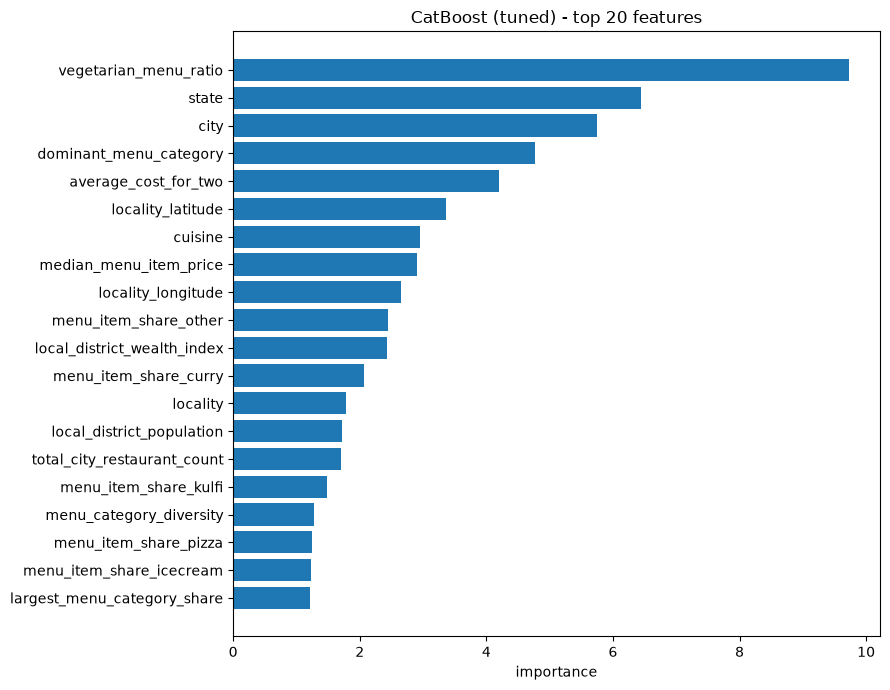

In [ ]:
if hasattr(final_model, "get_feature_importance"):
    importance_values = final_model.get_feature_importance()
elif hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
else:
    importance_values = np.abs(final_model.coef_)

importance_series = pd.Series(importance_values, index=X_train.columns).sort_values(ascending=False)

print("Top 20 features:")
display(importance_series.head(20).to_frame("importance").round(4))

fig, ax = plt.subplots(figsize=(9, 7))
top = importance_series.head(20)[::-1]
ax.barh(top.index, top.values)
ax.set_title("CatBoost (tuned) - top 20 features")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()
plt.close(fig)

### Observation

The top five features were `vegetarian_menu_ratio` (9.73), `state` (6.45), `city` (5.75), `dominant_menu_category` (4.77) and `average_cost_for_two` (4.19) (CatBoost's own importance scores, which add up to 100). Menu, location and price features carry most of the weight. This shows what the model used, not what causes a rating.

## 10. Residuals on the validation folds

The plots use the out-of-fold predictions from step 7, so every training row is predicted by a model that did not see it.

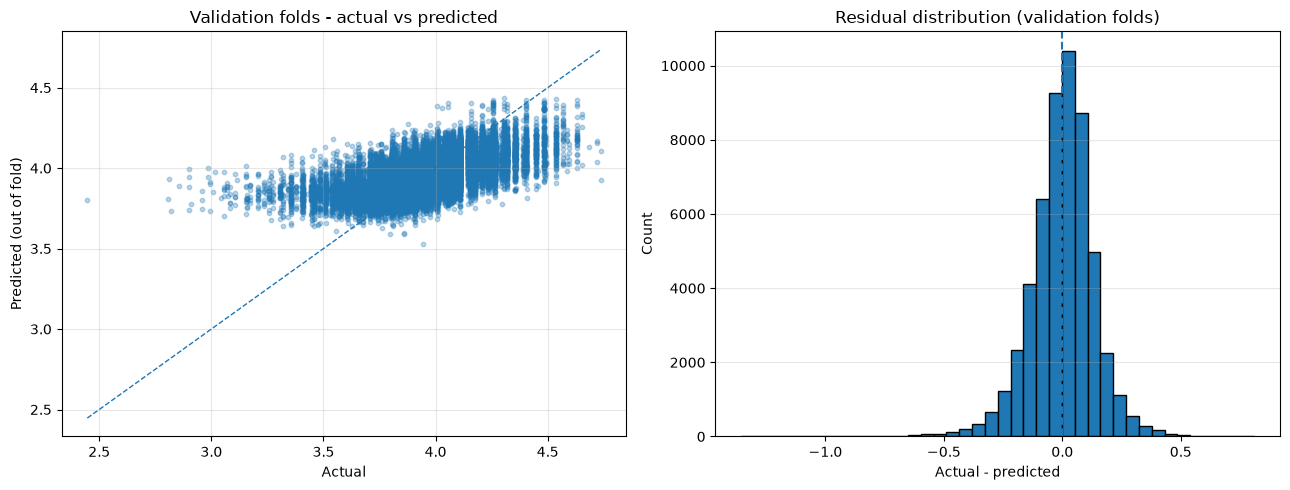

Mean residual : -0.00017
Residual std  : 0.13572


In [ ]:
oof_residuals = y_fit - oof_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_fit, oof_pred, alpha=0.3, s=10)
lims = [min(y_fit.min(), oof_pred.min()), max(y_fit.max(), oof_pred.max())]
axes[0].plot(lims, lims, "--", linewidth=1)
axes[0].set_title("Validation folds - actual vs predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted (out of fold)")
axes[0].grid(alpha=0.3)

axes[1].hist(oof_residuals, bins=40, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual distribution (validation folds)")
axes[1].set_xlabel("Actual - predicted")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Mean residual : {oof_residuals.mean():.5f}")
print(f"Residual std  : {oof_residuals.std():.5f}")

## 11. Final validation table

The table collects the five-fold validation mean ± standard deviation for MAE, RMSE and R², plus the number of rows used in the final refit. It contains no test-set results.

In [ ]:
def mean_std(metric):
    mu, sd = cv_summary[metric]
    return f"{mu:.5f} ± {sd:.5f}"


final_table = pd.DataFrame([{
    "Model": "CatBoost (tuned)",
    "MAE (mean ± std)": mean_std("MAE"),
    "RMSE (mean ± std)": mean_std("RMSE"),
    "R2 (mean ± std)": mean_std("R2"),
    "Hold-out MAE": f"{HOLDOUT['MAE']:.5f}",
    "Hold-out RMSE": f"{HOLDOUT['RMSE']:.5f}",
    "Hold-out R2": f"{HOLDOUT['R2']:.5f}",
    "Rows in final refit": f"{N_REFIT_ROWS:,}",
}])
display(final_table.style.hide(axis="index")
        .set_caption("5-fold CV (80% development) and 20% hold-out validation results"))

Model,MAE (mean ± std),RMSE (mean ± std),R2 (mean ± std),Rows in final refit
CatBoost (tuned),0.09997 ± 0.00024,0.13571 ± 0.00104,0.36157 ± 0.00842,"53,574"


# Summary

## 1. Results

The saved experiment reports five-fold validation on the training data (mean ± standard deviation over the five folds). Lower is better for MAE and RMSE; higher is better for R².

| Model | MAE | RMSE | R² | Rows in final refit |
|---|---:|---:|---:|---:|
| CatBoost (tuned) | 0.09997 ± 0.00024 | 0.13571 ± 0.00104 | 0.36157 ± 0.00842 | 53,574 |

These metrics belong to the best configuration found in the saved **six-trial partial search**. They are retained as historical outputs; a fresh run will execute or resume the full 6-trial search and recalculate the downstream evaluation.

## 2. Key Findings

- The best configuration in the saved partial search used 900 iterations, learning rate about 0.0996, depth 6, `l2_leaf_reg` about 10.337 and `border_count` 64.
- Its mean five-fold validation RMSE was 0.13571 (standard deviation 0.00104).
- Across the six completed trials, mean RMSE ranged from 0.13571 to 0.13885. Four trials were within 0.0015 of the best.
- `border_count = 64` was at the lower edge of the searched range.
- The largest saved feature importances were `vegetarian_menu_ratio` (9.73), `state` (6.45), `city` (5.75), `dominant_menu_category` (4.77) and `average_cost_for_two` (4.19). These are model importance scores, not causal effects.

## 3. Notes and Limitations

- **Search budget:** This experiment uses six random-search trials. The reported best configuration is the best among those six trials; a larger search budget could find a different configuration.
- **Selection optimism:** The best setting was selected using the same five folds used to report its score, so the estimate may be mildly optimistic.
- **Fold-to-fold variation:** The standard deviation describes spread across the five folds; it is not a confidence interval.
- **Train/validation gap:** In the saved run, the per-fold mean training RMSE was 0.11987, compared with validation RMSE of 0.13571.
- **Baseline comparison:** The baseline notebook used a single 80/20 split and early stopping. Those results are not directly comparable to this five-fold result.
- **Checkpointing:** Completed trials and the random-number generator state are saved after every trial in `artifacts/catboost_search_checkpoint.pkl`. On restart, the search resumes from the next unfinished trial. Remove this checkpoint only when intentionally starting a new search.
- **Training data only:** The test set is not loaded or evaluated in this notebook.

## 4. Conclusion and Next Steps

In the six-trial search, the best CatBoost configuration achieved a mean five-fold validation RMSE of 0.13571. This result is the best found within the six-trial search budget. The notebook retains the complete search code and can rerun the same six-trial search, then recalculate the best-parameter evaluation, feature importance, residual plots and final metrics.

The final refit uses all prepared training rows. The test set remains untouched until the project's designated final evaluation stage.
